# 01 — Preprocessing & Train/Val/Test Split

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)

In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

## 2. Load & Inspect the Data

In [3]:
df = pd.read_csv('arXiv_scientific_dataset.csv')

In [4]:
df.head(10)

,id,title,category,category_code,published_date,updated_date,authors,first_author,summary,summary_word_count
0,cs-9308101v1,Dynamic Backtracking,Artificial Intelligence,cs.AI,8/1/93,8/1/93,['M. L. Ginsberg'],'M. L. Ginsberg',"Because of their occasional need to return to shallow points in a search\ntree, existing backtracking methods can sometimes erase meaningful progr...",79
1,cs-9308102v1,A Market-Oriented Programming Environment and its Application to\n Distributed Multicommodity Flow Problems,Artificial Intelligence,cs.AI,8/1/93,8/1/93,['M. P. Wellman'],'M. P. Wellman',Market price systems constitute a well-understood class of mechanisms that\nunder certain conditions provide effective decentralization of decisio...,119
2,cs-9309101v1,An Empirical Analysis of Search in GSAT,Artificial Intelligence,cs.AI,9/1/93,9/1/93,"['I. P. Gent', 'T. Walsh']",'I. P. Gent',"We describe an extensive study of search in GSAT, an approximation procedure\nfor propositional satisfiability. GSAT performs greedy hill-climbing...",167
3,cs-9311101v1,The Difficulties of Learning Logic Programs with Cut,Artificial Intelligence,cs.AI,11/1/93,11/1/93,"['F. Bergadano', 'D. Gunetti', 'U. Trinchero']",'F. Bergadano',"As real logic programmers normally use cut (!), an effective learning\nprocedure for logic programs should be able to deal with it. Because the cu...",174
4,cs-9311102v1,Software Agents: Completing Patterns and Constructing User Interfaces,Artificial Intelligence,cs.AI,11/1/93,11/1/93,"['J. C. Schlimmer', 'L. A. Hermens']",'J. C. Schlimmer',"To support the goal of allowing users to record and retrieve information,\nthis paper describes an interactive note-taking system for pen-based co...",187
5,cs-9312101v1,Decidable Reasoning in Terminological Knowledge Representation Systems,Artificial Intelligence,cs.AI,12/1/93,12/1/93,"['M. Buchheit', 'F. M. Donini', 'A. Schaerf']",'M. Buchheit',Terminological knowledge representation systems (TKRSs) are tools for\ndesigning and using knowledge bases that make use of terminological languag...,161
6,cs-9401101v1,Teleo-Reactive Programs for Agent Control,Artificial Intelligence,cs.AI,1/1/94,1/1/94,['N. Nilsson'],'N. Nilsson',A formalism is presented for computing and organizing actions for autonomous\nagents in dynamic environments. We introduce the notion of teleo-rea...,144
7,cs-9402101v1,Learning the Past Tense of English Verbs: The Symbolic Pattern\n Associator vs. Connectionist Models,Artificial Intelligence,cs.AI,2/1/94,2/1/94,['C. X. Ling'],'C. X. Ling',"Learning the past tense of English verbs - a seemingly minor aspect of\nlanguage acquisition - has generated heated debates since 1986, and has be...",132
8,cs-9402102v1,Substructure Discovery Using Minimum Description Length and Background\n Knowledge,Artificial Intelligence,cs.AI,2/1/94,2/1/94,"['D. J. Cook', 'L. B. Holder']",'D. J. Cook',The ability to identify interesting and repetitive substructures is an\nessential component to discovering knowledge in structural data. We descri...,194
9,cs-9402103v1,Bias-Driven Revision of Logical Domain Theories,Artificial Intelligence,cs.AI,2/1/94,2/1/94,"['M. Koppel', 'R. Feldman', 'A. M. Segre']",'M. Koppel',The theory revision problem is the problem of how best to go about revising a\ndeficient domain theory using information contained in examples tha...,130


In [5]:
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 287421
Number of Columns: 10


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 287421 entries, 0 to 287420
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   id                  287421 non-null  str  
 1   title               287421 non-null  str  
 2   category            287421 non-null  str  
 3   category_code       287421 non-null  str  
 4   published_date      287421 non-null  str  
 5   updated_date        287421 non-null  str  
 6   authors             287421 non-null  str  
 7   first_author        287421 non-null  str  
 8   summary             287421 non-null  str  
 9   summary_word_count  287421 non-null  int64
dtypes: int64(1), str(9)
memory usage: 427.4 MB


## 3. Missing Values & Duplicates

In [7]:
df.isnull().sum()

id                    0
title                 0
category              0
category_code         0
published_date        0
updated_date          0
authors               0
first_author          0
summary               0
summary_word_count    0
dtype: int64

In [8]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate titles:', df['title'].duplicated().sum())
print('Duplicate summaries:', df['summary'].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 115
Duplicate summaries: 64


## 4. Class Distribution & Target Class Selection

In [9]:
df['category'].value_counts().head(15)

category
Machine Learning                                          80452
Computer Vision and Pattern Recognition                   71106
Computation and Language (Natural Language Processing)    37251
Artificial Intelligence                                   28726
Machine Learning (Statistics)                             13892
Neural and Evolutionary Computing                          6715
Robotics                                                   5254
Cryptography and Security                                  4376
Image and Video Processing                                 2771
Information Retrieval                                      2712
Software Engineering                                       2575
Computers and Society                                      2293
Human-Computer Interaction                                 2184
Sound                                                      1733
Methodology (Statistics)                                   1616
Name: count, dtype: int64

In [10]:
top_classes = [
    'Machine Learning',
    'Computer Vision and Pattern Recognition',
    'Computation and Language (Natural Language Processing)',
    'Artificial Intelligence',
    'Machine Learning (Statistics)',
    'Neural and Evolutionary Computing'
]

data = df[df['category'].isin(top_classes)].copy()
data = data.reset_index(drop=True)
data.shape

(238142, 10)

## 5. Exploratory Data Analysis

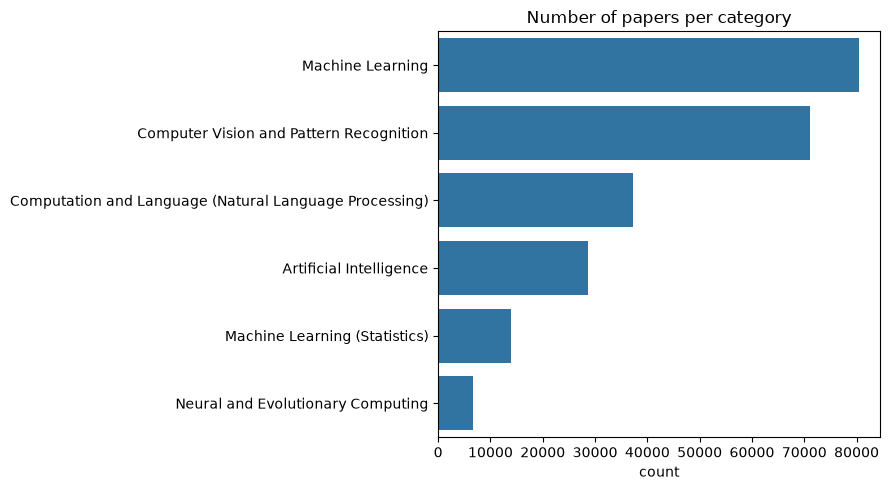

In [11]:
plt.figure(figsize=(9,5))
order = data['category'].value_counts().index
sns.countplot(data=data, y='category', order=order)
plt.title('Number of papers per category')
plt.xlabel('count')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [12]:
data['summary_word_count'].describe()

count    238142.000000
mean        170.120281
std          45.467549
min           1.000000
25%         140.000000
50%         170.000000
75%         200.000000
max         552.000000
Name: summary_word_count, dtype: float64

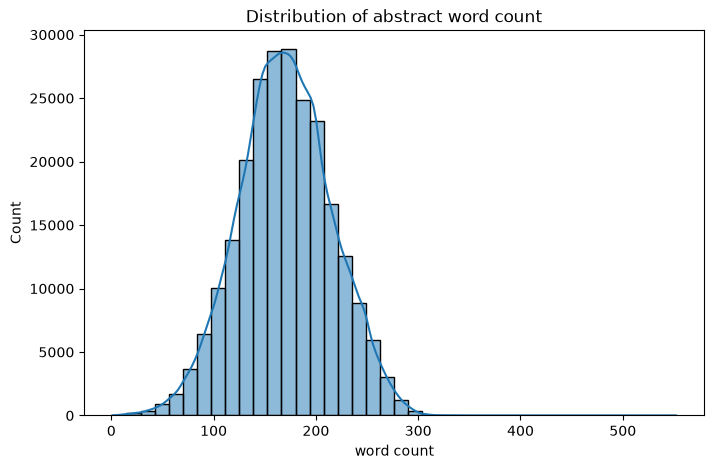

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(data['summary_word_count'], bins=40, kde=True)
plt.title('Distribution of abstract word count')
plt.xlabel('word count')
plt.show()

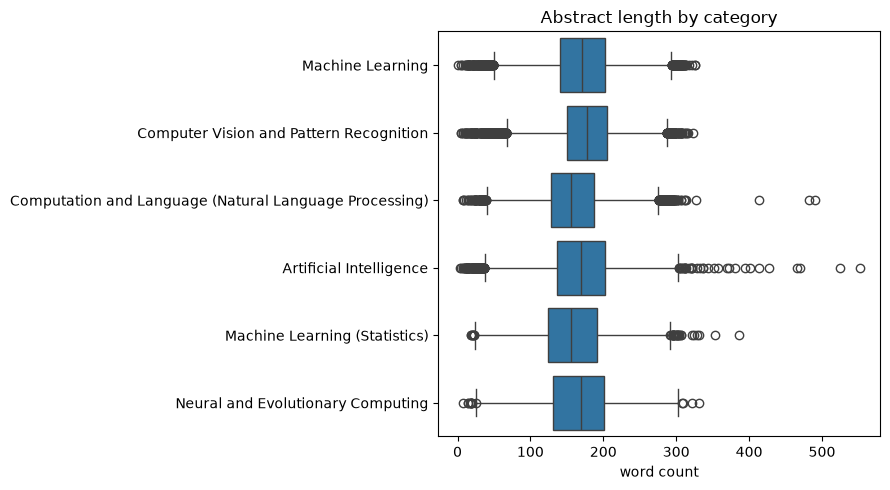

In [14]:
plt.figure(figsize=(9,5))
sns.boxplot(data=data, x='summary_word_count', y='category', order=order)
plt.title('Abstract length by category')
plt.xlabel('word count')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [15]:
print('duplicate summaries in the filtered data:', data['summary'].duplicated().sum())
data = data.drop_duplicates(subset='summary').reset_index(drop=True)
data.shape

duplicate summaries in the filtered data: 58


(238084, 10)

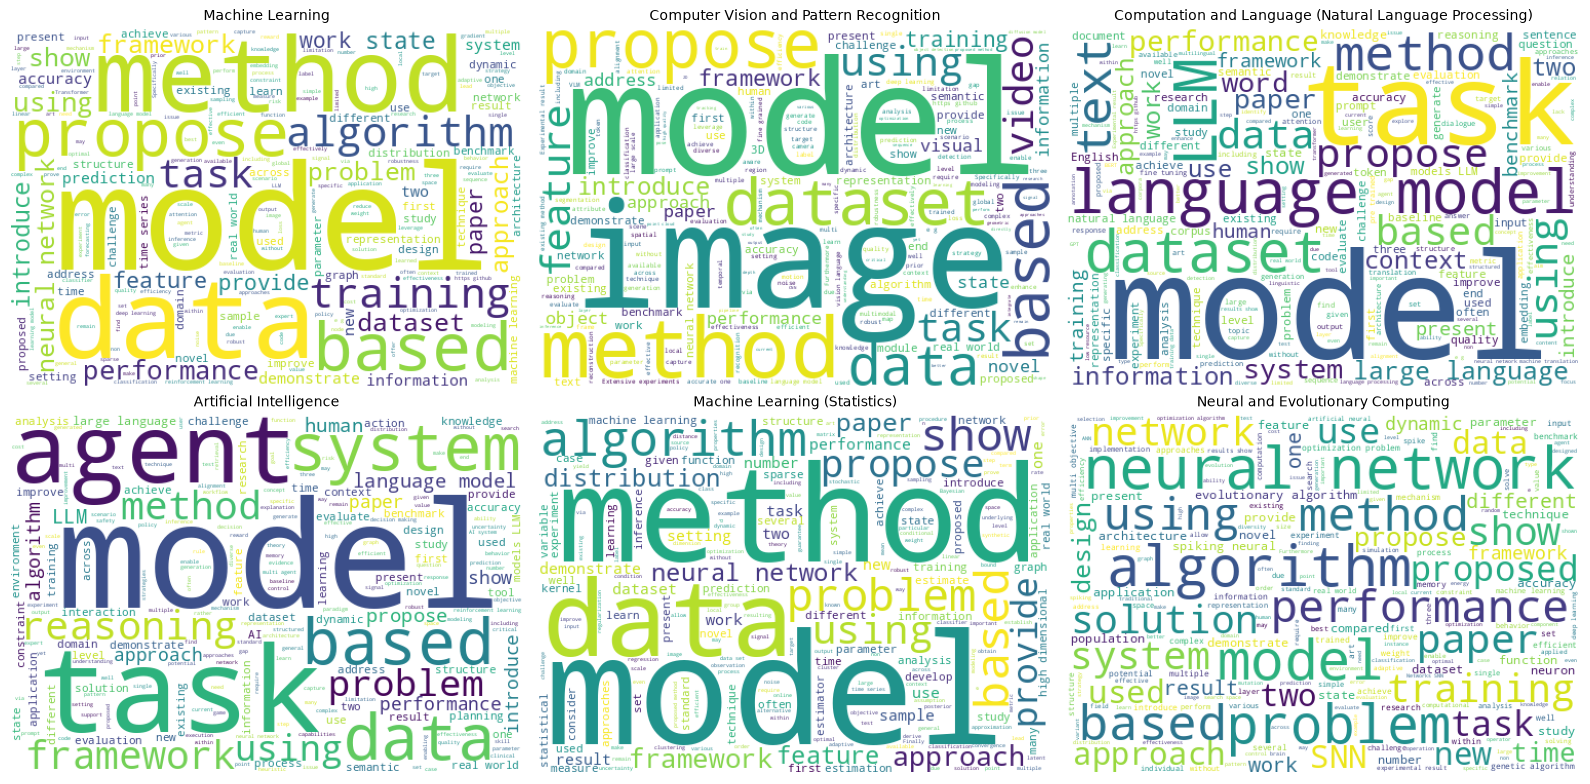

In [16]:
from wordcloud import WordCloud

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()

for ax, cat in zip(axes, top_classes):
    text = ' '.join(data[data['category'] == cat]['summary'].sample(min(2000, (data['category']==cat).sum()), random_state=RANDOM_STATE))
    wc = WordCloud(width=500, height=350, background_color='white', stopwords=None).generate(text)
    ax.imshow(wc)
    ax.set_title(cat, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Text Cleaning

In [17]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/halululu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/halululu/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/halululu/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/halululu/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [18]:
def basic_clean(text):
    text = text.replace('\n', ' ')
    text = re.sub(r'\$.*?\$', ' ', text)      # strip inline LaTeX math ($...$)
    text = re.sub(r'\\[a-zA-Z]+', ' ', text)   # strip LaTeX commands (\alpha, \frac, ...)
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)       # drop digits & punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

sample = data['summary'].iloc[1]
print('Prev:\n', sample[:300])
print('\nCurrent:\n', basic_clean(sample)[:300])

Prev:
 Market price systems constitute a well-understood class of mechanisms that
under certain conditions provide effective decentralization of decision making
with minimal communication overhead. In a market-oriented programming approach
to distributed problem solving, we derive the activities and resour

Current:
 market price systems constitute a well understood class of mechanisms that under certain conditions provide effective decentralization of decision making with minimal communication overhead in a market oriented programming approach to distributed problem solving we derive the activities and resource


**Design decisions worth calling out in the report:**

In [19]:
def clean_no_stopwords_lemma(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

def clean_keep_stopwords_lemma(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if len(w) > 2]
    return ' '.join(tokens)

def clean_no_stopwords_stem(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

In [20]:
sample_df = data.sample(2000, random_state=RANDOM_STATE)

v1 = sample_df['summary'].apply(clean_no_stopwords_lemma)
v2 = sample_df['summary'].apply(clean_keep_stopwords_lemma)
v3 = sample_df['summary'].apply(clean_no_stopwords_stem)

def vocab_size(series):
    words = set()
    for t in series:
        words.update(t.split())
    return len(words)

def avg_len(series):
    return series.apply(lambda t: len(t.split())).mean()

print('no stopwords + lemmatize   -> vocab:', vocab_size(v1), ' avg words/doc:', round(avg_len(v1),1))
print('keep stopwords + lemmatize -> vocab:', vocab_size(v2), ' avg words/doc:', round(avg_len(v2),1))
print('no stopwords + stemming    -> vocab:', vocab_size(v3), ' avg words/doc:', round(avg_len(v3),1))

no stopwords + lemmatize   -> vocab: 12668  avg words/doc: 115.2
keep stopwords + lemmatize -> vocab: 12761  avg words/doc: 146.8
no stopwords + stemming    -> vocab: 8854  avg words/doc: 115.2


In [21]:
print(sample_df['summary'].iloc[0][:250], '\n')
print('no stopwords + lemma :', v1.iloc[0][:250], '\n')
print('keep stopwords       :', v2.iloc[0][:250], '\n')
print('no stopwords + stem  :', v3.iloc[0][:250])

Language models pre-trained on general text have achieved impressive results
in diverse fields. Yet, the distinct linguistic characteristics of
task-oriented dialogues (TOD) compared to general text limit the practical
utility of existing language mo 

no stopwords + lemma : language model pre trained general text achieved impressive result diverse field yet distinct linguistic characteristic task oriented dialogue tod compared general text limit practical utility existing language model current task oriented dialogue pr 

keep stopwords       : language model pre trained general text have achieved impressive result diverse field yet the distinct linguistic characteristic task oriented dialogue tod compared general text limit the practical utility existing language model current task oriente 

no stopwords + stem  : languag model pre train gener text achiev impress result divers field yet distinct linguist characterist task orient dialogu tod compar gener text limit practic util exist 

## 7. Apply Final Cleaning & Post-Cleaning QA

In [22]:
data['clean_summary'] = data['summary'].apply(clean_no_stopwords_lemma)
data[['summary', 'clean_summary']].head()

,summary,clean_summary
0,"Because of their occasional need to return to shallow points in a search\ntree, existing backtracking methods can sometimes erase meaningful progr...",occasional need return shallow point search tree existing backtracking method sometimes erase meaningful progress toward solving search problem pa...
1,Market price systems constitute a well-understood class of mechanisms that\nunder certain conditions provide effective decentralization of decisio...,market price system constitute well understood class mechanism certain condition provide effective decentralization decision making minimal commun...
2,"We describe an extensive study of search in GSAT, an approximation procedure\nfor propositional satisfiability. GSAT performs greedy hill-climbing...",describe extensive study search gsat approximation procedure propositional satisfiability gsat performs greedy hill climbing number satisfied clau...
3,"As real logic programmers normally use cut (!), an effective learning\nprocedure for logic programs should be able to deal with it. Because the cu...",real logic programmer normally use cut effective learning procedure logic program able deal cut predicate procedural meaning clause containing cut...
4,"To support the goal of allowing users to record and retrieve information,\nthis paper describes an interactive note-taking system for pen-based co...",support goal allowing user record retrieve information paper describes interactive note taking system pen based computer two distinctive feature f...


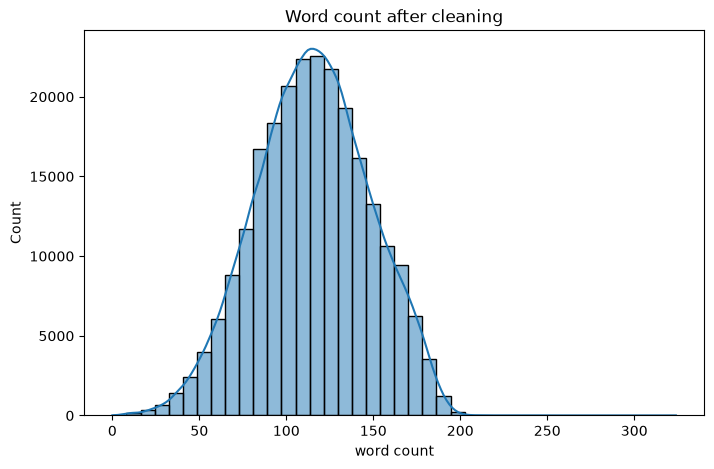

count    238084.000000
mean        115.236761
std          32.694840
min           0.000000
25%          93.000000
50%         115.000000
75%         138.000000
max         324.000000
Name: clean_word_count, dtype: float64

In [23]:
data['clean_word_count'] = data['clean_summary'].apply(lambda t: len(t.split()))

plt.figure(figsize=(8,5))
sns.histplot(data['clean_word_count'], bins=40, kde=True)
plt.title('Word count after cleaning')
plt.xlabel('word count')
plt.show()

data['clean_word_count'].describe()

In [24]:
# Explicit, order-independent check (don't rely on .describe() min alone)
n_empty = int((data['clean_word_count'] == 0).sum())
print('rows that became empty after cleaning:', n_empty)

data = data[data['clean_word_count'] > 0].reset_index(drop=True)
print('shape after removing empty-after-cleaning rows:', data.shape)

rows that became empty after cleaning: 1
shape after removing empty-after-cleaning rows: (238083, 12)


In [25]:
MIN_TOKENS = 10
short_count = int((data['clean_word_count'] < MIN_TOKENS).sum())
print(f'abstracts with fewer than {MIN_TOKENS} tokens after cleaning:', short_count)

data = data[data['clean_word_count'] >= MIN_TOKENS].reset_index(drop=True)
print('final shape after short-document filter:', data.shape)

abstracts with fewer than 10 tokens after cleaning: 71
final shape after short-document filter: (238012, 12)


## 8. Class Distribution After Cleaning & Imbalance Handling

In [26]:
data['category'].value_counts()

category
Machine Learning                                          80413
Computer Vision and Pattern Recognition                   71081
Computation and Language (Natural Language Processing)    37243
Artificial Intelligence                                   28679
Machine Learning (Statistics)                             13886
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

In [27]:
CAP = 12000  # cap per class; tune down further if training time is still too long on your GPU

parts = []
for cat, g in data.groupby('category'):
    parts.append(g.sample(n=min(len(g), CAP), random_state=RANDOM_STATE))

data_capped = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print('Before capping:')
print(data['category'].value_counts())
print('\nAfter capping (CAP =', CAP, '):')
print(data_capped['category'].value_counts())
print('\nImbalance ratio before:', round(data['category'].value_counts().max() / data['category'].value_counts().min(), 2))
print('Imbalance ratio after :', round(data_capped['category'].value_counts().max() / data_capped['category'].value_counts().min(), 2))

Before capping:
category
Machine Learning                                          80413
Computer Vision and Pattern Recognition                   71081
Computation and Language (Natural Language Processing)    37243
Artificial Intelligence                                   28679
Machine Learning (Statistics)                             13886
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

After capping (CAP = 12000 ):
category
Machine Learning                                          12000
Computer Vision and Pattern Recognition                   12000
Machine Learning (Statistics)                             12000
Artificial Intelligence                                   12000
Computation and Language (Natural Language Processing)    12000
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

Imbalance ratio before: 11.98
Imbalance ratio after : 1.79


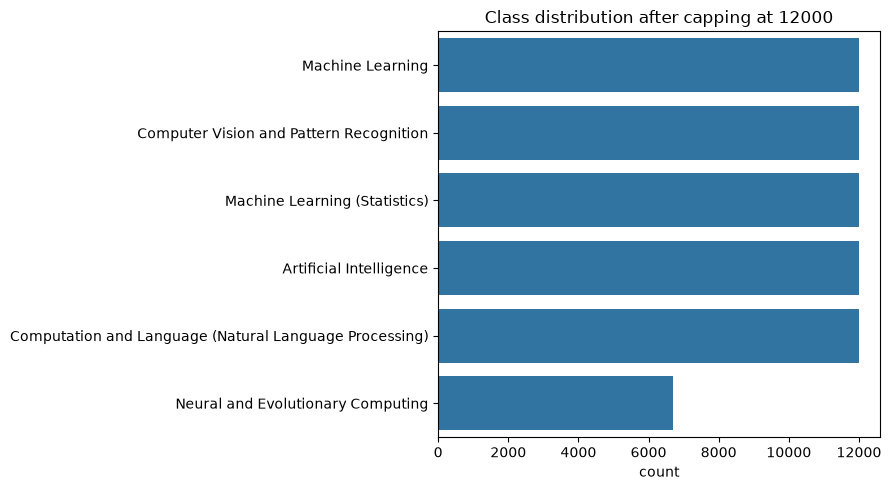

In [28]:
plt.figure(figsize=(9,5))
sns.countplot(data=data_capped, y='category', order=data_capped['category'].value_counts().index)
plt.title(f'Class distribution after capping at {CAP}')
plt.xlabel('count')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 9. Save Cleaned Data

In [29]:
data.to_csv('arxiv_cleaned_full.csv', index=False)
data_capped.to_csv('arxiv_cleaned_capped.csv', index=False)
print('saved full cleaned set:', data.shape)
print('saved capped modeling set:', data_capped.shape)

saved full cleaned set: (238012, 12)
saved capped modeling set: (66710, 12)


## 10. Train / Validation / Test Split


In [30]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data_capped, test_size=0.30, stratify=data_capped['category'], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['category'], random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('train:', train_df.shape, ' val:', val_df.shape, ' test:', test_df.shape)
print('\ntrain class distribution:\n', train_df['category'].value_counts(normalize=True).round(3))

train: (46697, 12)  val: (10006, 12)  test: (10007, 12)

train class distribution:
 category
Artificial Intelligence                                   0.180
Computation and Language (Natural Language Processing)    0.180
Computer Vision and Pattern Recognition                   0.180
Machine Learning                                          0.180
Machine Learning (Statistics)                             0.180
Neural and Evolutionary Computing                         0.101
Name: proportion, dtype: float64


In [31]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

num_classes = len(label_encoder.classes_)
print('classes:', list(label_encoder.classes_))
print('num_classes:', num_classes)

classes: ['Artificial Intelligence', 'Computation and Language (Natural Language Processing)', 'Computer Vision and Pattern Recognition', 'Machine Learning', 'Machine Learning (Statistics)', 'Neural and Evolutionary Computing']
num_classes: 6


In [32]:
from sklearn.utils.class_weight import compute_class_weight

class_weight_values = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weight_values)}
print('class weights (used to counter residual imbalance during training):')
for i, cls in enumerate(label_encoder.classes_):
    print(f'  {cls:60s} -> {class_weight_dict[i]:.3f}')

class weights (used to counter residual imbalance during training):
  Artificial Intelligence                                      -> 0.927
  Computation and Language (Natural Language Processing)       -> 0.927
  Computer Vision and Pattern Recognition                      -> 0.927
  Machine Learning                                             -> 0.927
  Machine Learning (Statistics)                                -> 0.927
  Neural and Evolutionary Computing                            -> 1.657


## Handoff to Notebook 2/3/4

In [33]:
import joblib

train_df.to_csv('train_df.csv', index=False)
val_df.to_csv('val_df.csv', index=False)
test_df.to_csv('test_df.csv', index=False)

joblib.dump(label_encoder, 'label_encoder.joblib')
joblib.dump(class_weight_dict, 'class_weight_dict.joblib')

print('Saved train_df, val_df, test_df, label_encoder, class_weight_dict.')
print('You can now close this kernel and open 02_classical_ml.ipynb, 03_rnn_family.ipynb, and/or 04_bert.ipynb independently.')

Saved train_df, val_df, test_df, label_encoder, class_weight_dict.
You can now close this kernel and open 02_classical_ml.ipynb, 03_rnn_family.ipynb, and/or 04_bert.ipynb independently.


# 02 — Classical ML Models (TF-IDF)

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)



In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

## 0. Reload Pipeline State from Notebook 1

In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


### 11.1 TF-IDF

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['clean_summary'])
X_val_tfidf = tfidf_vectorizer.transform(val_df['clean_summary'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['clean_summary'])

print('TF-IDF shapes -> train:', X_train_tfidf.shape, ' val:', X_val_tfidf.shape, ' test:', X_test_tfidf.shape)

TF-IDF shapes -> train: (46697, 20000)  val: (10006, 20000)  test: (10007, 20000)


## 12. Classical ML Models


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# tuning_log, log_run(), and best_config_row() are defined once in Section 1.1 (run that cell
# first if you haven't this session) so they persist across kernel restarts between sections.

def evaluate_on_val(model, X_val, y_val):
    pred = model.predict(X_val)
    return accuracy_score(y_val, pred), f1_score(y_val, pred, average='macro')

In [6]:
# ---- Random Forest: 3 configs ----
import joblib

rf_configs = [
    {'n_estimators': 100, 'max_depth': None},
    {'n_estimators': 300, 'max_depth': 40},
    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2},
]

rf_models = {}
for cfg in rf_configs:
    path = classical_model_path('RandomForest', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced', **cfg)
        clf.fit(X_train_tfidf, y_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('RandomForest', cfg, acc, f1m)
    rf_models[str(cfg)] = clf

Trained and saved to saved_models/classical/RandomForest__ed7188d076.joblib
RandomForest           {'n_estimators': 100, 'max_depth': None}                val_acc=0.7208  val_f1_macro=0.7174
Trained and saved to saved_models/classical/RandomForest__e47df04109.joblib
RandomForest           {'n_estimators': 300, 'max_depth': 40}                  val_acc=0.7225  val_f1_macro=0.7149
Trained and saved to saved_models/classical/RandomForest__1dce76fbe1.joblib
RandomForest           {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2} val_acc=0.7266  val_f1_macro=0.7206


In [7]:
# ---- Logistic Regression: 3 configs ----
lr_configs = [
    {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000},
    {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000},
    {'C': 5.0, 'solver': 'saga', 'max_iter': 2000},
]

lr_models = {}
for cfg in lr_configs:
    path = classical_model_path('LogisticRegression', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, **cfg)
        clf.fit(X_train_tfidf, y_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('LogisticRegression', cfg, acc, f1m)
    lr_models[str(cfg)] = clf

Trained and saved to saved_models/classical/LogisticRegression__2880cc8e2e.joblib
LogisticRegression     {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000}         val_acc=0.7472  val_f1_macro=0.7467
Trained and saved to saved_models/classical/LogisticRegression__43399c2aa2.joblib
LogisticRegression     {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}         val_acc=0.7618  val_f1_macro=0.7629
Trained and saved to saved_models/classical/LogisticRegression__8c0f3b994d.joblib
LogisticRegression     {'C': 5.0, 'solver': 'saga', 'max_iter': 2000}          val_acc=0.7438  val_f1_macro=0.7467


In [8]:
# ---- Naive Bayes: 3 configs ----
# MultinomialNB has no native class_weight param; we approximate class balancing via `sample_weight` at fit time.
from sklearn.utils.class_weight import compute_sample_weight
sample_weights_train = compute_sample_weight('balanced', y_train)

nb_configs = [
    {'alpha': 0.1},
    {'alpha': 0.5},
    {'alpha': 1.0},
]

nb_models = {}
for cfg in nb_configs:
    path = classical_model_path('NaiveBayes', cfg)
    if os.path.exists(path):
        print(f'Already trained -- loading {path}')
        clf = joblib.load(path)
    else:
        clf = MultinomialNB(**cfg)
        clf.fit(X_train_tfidf, y_train, sample_weight=sample_weights_train)
        joblib.dump(clf, path)
        print(f'Trained and saved to {path}')
    acc, f1m = evaluate_on_val(clf, X_val_tfidf, y_val)
    log_run('NaiveBayes', cfg, acc, f1m)
    nb_models[str(cfg)] = clf

Trained and saved to saved_models/classical/NaiveBayes__04f74f957c.joblib
NaiveBayes             {'alpha': 0.1}                                          val_acc=0.7430  val_f1_macro=0.7425
Trained and saved to saved_models/classical/NaiveBayes__223fdb7ae0.joblib
NaiveBayes             {'alpha': 0.5}                                          val_acc=0.7454  val_f1_macro=0.7430
Trained and saved to saved_models/classical/NaiveBayes__b99b020128.joblib
NaiveBayes             {'alpha': 1.0}                                          val_acc=0.7436  val_f1_macro=0.7403


In [9]:
tuning_log_df = pd.DataFrame(tuning_log)
tuning_log_df

,model,config,val_accuracy,val_f1_macro
0,RandomForest,"{'n_estimators': 100, 'max_depth': None}",0.720768,0.717429
1,RandomForest,"{'n_estimators': 300, 'max_depth': 40}",0.722467,0.714878
2,RandomForest,"{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2}",0.726564,0.720621
3,LogisticRegression,"{'C': 0.1, 'solver': 'lbfgs', 'max_iter': 1000}",0.747152,0.746716
4,LogisticRegression,"{'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}",0.761843,0.762877
5,LogisticRegression,"{'C': 5.0, 'solver': 'saga', 'max_iter': 2000}",0.743754,0.746717
6,NaiveBayes,{'alpha': 0.1},0.742954,0.742495
7,NaiveBayes,{'alpha': 0.5},0.745353,0.742990
8,NaiveBayes,{'alpha': 1.0},0.743554,0.740266


Pick the best configuration per model family (highest validation macro-F1), then do the one-shot final evaluation on the held-out **test** set:

Best config for RandomForest: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2}  (val_f1_macro=0.7206)
=== RandomForest (test set) ===
Accuracy: 0.7238   Macro-F1: 0.7191   Weighted-F1: 0.7124
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.73      0.61      0.67      1800
Computation and Language (Natural Language Processing)       0.75      0.86      0.80      1800
               Computer Vision and Pattern Recognition       0.79      0.90      0.84      1800
                                      Machine Learning       0.62      0.39      0.48      1800
                         Machine Learning (Statistics)       0.65      0.80      0.72      1800
                     Neural and Evolutionary Computing       0.79      0.82      0.80      1007

                                              accuracy                           0.72     10007
                       

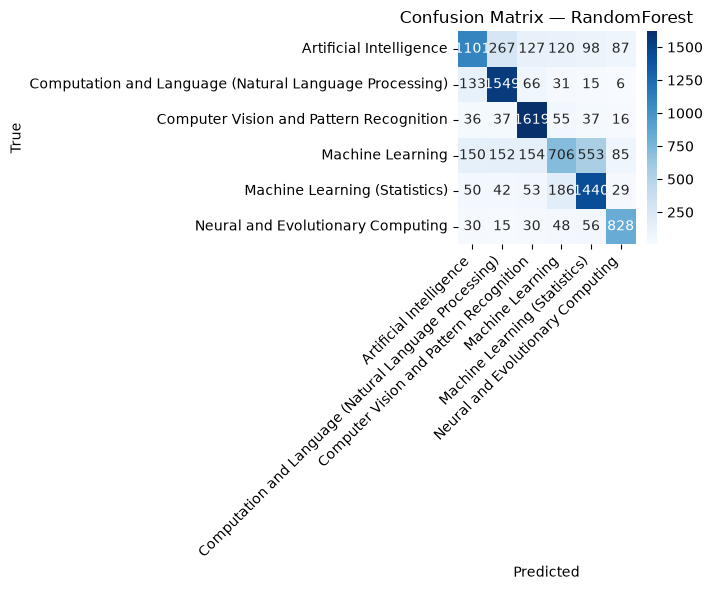

Best config for LogisticRegression: {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000}  (val_f1_macro=0.7629)
=== LogisticRegression (test set) ===
Accuracy: 0.7539   Macro-F1: 0.7563   Weighted-F1: 0.7522
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.72      0.70      0.71      1800
Computation and Language (Natural Language Processing)       0.82      0.83      0.82      1800
               Computer Vision and Pattern Recognition       0.87      0.88      0.88      1800
                                      Machine Learning       0.60      0.55      0.57      1800
                         Machine Learning (Statistics)       0.72      0.78      0.75      1800
                     Neural and Evolutionary Computing       0.79      0.82      0.81      1007

                                              accuracy                           0.75     10007
                           

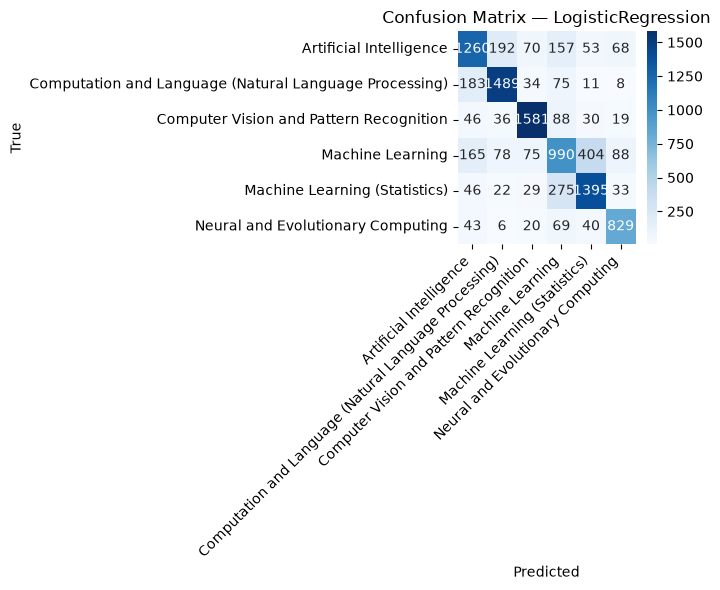

Best config for NaiveBayes: {'alpha': 0.5}  (val_f1_macro=0.7430)
=== NaiveBayes (test set) ===
Accuracy: 0.7412   Macro-F1: 0.7398   Weighted-F1: 0.7359
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.70      0.69      0.69      1800
Computation and Language (Natural Language Processing)       0.82      0.83      0.82      1800
               Computer Vision and Pattern Recognition       0.86      0.86      0.86      1800
                                      Machine Learning       0.64      0.47      0.54      1800
                         Machine Learning (Statistics)       0.68      0.80      0.74      1800
                     Neural and Evolutionary Computing       0.74      0.85      0.79      1007

                                              accuracy                           0.74     10007
                                             macro avg       0.74      0.75 

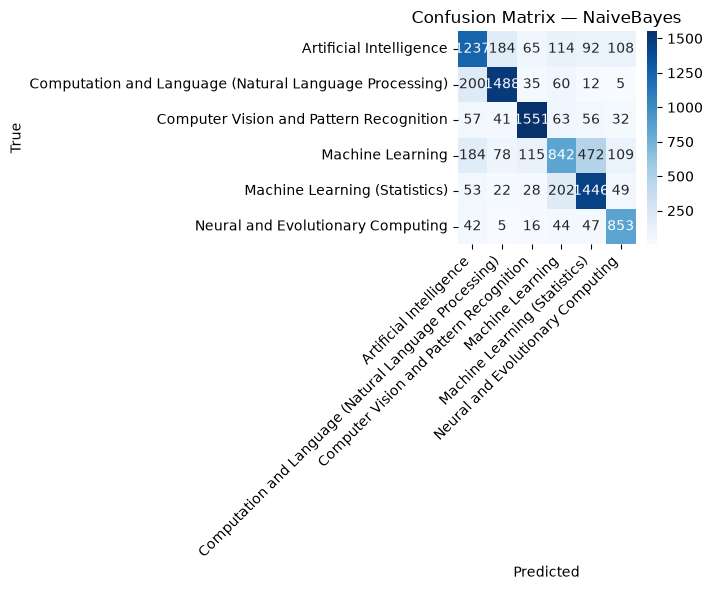

In [10]:
# best_config_row() is already defined in Section 1.1. final_results is also already
# defined there (and persisted to final_results.csv) so it survives kernel restarts.
classical_models = {'RandomForest': rf_models, 'LogisticRegression': lr_models, 'NaiveBayes': nb_models}

def evaluate_on_test(model_name, model, X_test, y_test, label_encoder):
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1_macro = f1_score(y_test, pred, average='macro')
    f1_weighted = f1_score(y_test, pred, average='weighted')
    cm = confusion_matrix(y_test, pred)
    report = classification_report(y_test, pred, target_names=label_encoder.classes_)

    print(f'=== {model_name} (test set) ===')
    print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
    print(report)

    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    record_final_result(model_name, acc, f1_macro, f1_weighted)
    return pred

for model_name, model_dict in classical_models.items():
    best_row = best_config_row(tuning_log_df, model_name)
    best_cfg = parse_config(best_row['config'])
    path = classical_model_path(model_name, best_cfg)
    best_model = model_dict.get(best_row['config']) or joblib.load(path)  # falls back to disk if this dict is from a fresh kernel
    print(f'Best config for {model_name}: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')
    evaluate_on_test(model_name, best_model, X_test_tfidf, y_test, label_encoder)

# 03 — RNN Family Models (Word2Vec)

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)

In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

Reloaded 9 existing tuning_log rows from tuning_log.csv
Reloaded 3 existing final_results rows from final_results.csv


## 0. Reload Pipeline State from Notebook 1



In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

### 11.2 Word2Vec (self-trained on the training corpus)

In [5]:
from gensim.models import Word2Vec

EMBED_DIM = 200

tokenized_train = train_df['clean_summary'].apply(str.split).tolist()

w2v_model = Word2Vec(
    sentences=tokenized_train,
    vector_size=EMBED_DIM,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # skip-gram; generally stronger than CBOW for smaller/domain-specific corpora
    epochs=10,
    seed=RANDOM_STATE,
)

print('Word2Vec vocabulary size:', len(w2v_model.wv))
print('Most similar to "neural":', w2v_model.wv.most_similar('neural', topn=5))

Word2Vec vocabulary size: 41507
Most similar to "neural": [('network', 0.6635556817054749), ('grnn', 0.6453627943992615), ('ffnns', 0.6298272013664246), ('slfn', 0.6289162039756775), ('elman', 0.6253756284713745)]


## 13. Deep Learning Models — RNN Family

In [ ]:
import tensorflow as tf
print('GPUs visible to TensorFlow:', tf.config.list_physical_devices('GPU'))

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

I0000 00:00:1787484500.503342   16301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787484500.533758   16301 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787484501.845808   16301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPUs visible to TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
details = tf.config.experimental.get_device_details(tf.config.list_physical_devices('GPU')[0])
print(details)

{'compute_capability': (8, 6), 'device_name': 'NVIDIA GeForce RTX 3060'}


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB = 30000
MAX_LEN = 256  # covers the large majority of cleaned abstracts (see Section 5 word-count distribution)

keras_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
keras_tokenizer.fit_on_texts(train_df['clean_summary'])

X_train_seq = pad_sequences(keras_tokenizer.texts_to_sequences(train_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')
X_val_seq = pad_sequences(keras_tokenizer.texts_to_sequences(val_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')
X_test_seq = pad_sequences(keras_tokenizer.texts_to_sequences(test_df['clean_summary']), maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_VOCAB, len(keras_tokenizer.word_index) + 1)
print('Effective vocab size:', vocab_size)
print('Sequence shapes -> train:', X_train_seq.shape, ' val:', X_val_seq.shape, ' test:', X_test_seq.shape)

Effective vocab size: 30000
Sequence shapes -> train: (46697, 256)  val: (10006, 256)  test: (10007, 256)


In [ ]:
# Build an embedding matrix from the Word2Vec model trained in Section 11.2.
# Words in the Keras vocab but not in the Word2Vec vocab (rare/OOV words) get a zero vector.
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
hits, misses = 0, 0
for word, idx in keras_tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    if word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]
        hits += 1
    else:
        misses += 1

print(f'Embedding matrix: {hits} words matched to Word2Vec, {misses} words unmatched (left as zero vectors)')

Embedding matrix: 29998 words matched to Word2Vec, 1 words unmatched (left as zero vectors)


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, GRU, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

def build_rnn_model(cell_type, units, bidirectional, dropout, learning_rate):
    cell_cls = {'SimpleRNN': SimpleRNN, 'GRU': GRU, 'LSTM': LSTM}[cell_type]
    recurrent_layer = cell_cls(units, dropout=dropout)
    if bidirectional:
        recurrent_layer = Bidirectional(recurrent_layer)

    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=EMBED_DIM, weights=[embedding_matrix],
                  trainable=True, mask_zero=True),
        recurrent_layer,
        Dropout(dropout),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [11]:
rnn_architectures = [
    ('SimpleRNN', False),
    ('GRU', False),
    ('LSTM', False),
    ('SimpleRNN', True),
    ('GRU', True),
    ('LSTM', True),
]

rnn_hparam_configs = [
    {'units': 64,  'dropout': 0.2, 'learning_rate': 1e-3},
    {'units': 128, 'dropout': 0.3, 'learning_rate': 1e-3},
    {'units': 128, 'dropout': 0.3, 'learning_rate': 5e-4},
]

BATCH_SIZE = 128
EPOCHS = 15

rnn_trained_models = {}

for cell_type, bidirectional in rnn_architectures:
    arch_name = ('Bi' if bidirectional else '') + cell_type
    for cfg in rnn_hparam_configs:
        path = rnn_model_path(arch_name, cfg)
        if os.path.exists(path):
            print(f'Already trained -- loading {path}')
            model = tf.keras.models.load_model(path)
        else:
            tf.random.set_seed(RANDOM_STATE)
            model = build_rnn_model(cell_type, bidirectional=bidirectional, **cfg)
            es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

            model.fit(
                X_train_seq, y_train,
                validation_data=(X_val_seq, y_val),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weight_dict,
                callbacks=[es],
                verbose=0,
            )
            model.save(path)
            print(f'Trained and saved to {path}')

        val_pred = np.argmax(model.predict(X_val_seq, batch_size=BATCH_SIZE, verbose=0), axis=1)
        val_acc = accuracy_score(y_val, val_pred)
        val_f1 = f1_score(y_val, val_pred, average='macro')
        log_run(arch_name, cfg, val_acc, val_f1)
        rnn_trained_models[(arch_name, str(cfg))] = model

Already trained -- loading saved_models/rnn/SimpleRNN__c4de2d796c.keras


I0000 00:00:1787484505.590275   16301 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9707 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1787484506.424909   16842 service.cc:153] XLA service 0x7b39080401a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787484506.424948   16842 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1787484506.438064   16842 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787484506.460045   16842 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1787484506.628074   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not co

SimpleRNN              {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.5803  val_f1_macro=0.5542


I0000 00:00:1787484510.811202   16841 dot_merger.cc:481] Merging Dots in computation: sequential_1_simple_rnn_1_while_body_3328_grad_3565_const_0__.23.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787484510.811291   16841 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4271__.27
I0000 00:00:1787484510.845745   16841 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787484511.094121   17093 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_24', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1787484511.116299   16841 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good r

Trained and saved to saved_models/rnn/SimpleRNN__f38a7ac942.keras
SimpleRNN              {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.5587  val_f1_macro=0.4986


...

Trained and saved to saved_models/rnn/BiSimpleRNN__c4de2d796c.keras
BiSimpleRNN            {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.6828  val_f1_macro=0.6745


I0000 00:00:1787485638.144228   16835 dot_merger.cc:481] Merging Dots in computation: sequential_9_1_bidirectional_1_1_backward_simple_rnn_3_1_while_body_140079_grad_140684_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485638.144330   16835 dot_merger.cc:481] Merging Dots in computation: sequential_9_1_bidirectional_1_1_forward_simple_rnn_3_1_while_body_139906_grad_140334_const_0__.35.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485638.144378   16835 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_141519__.39
I0000 00:00:1787485638.271709   16835 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787485638.531631   25316 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory i

Trained and saved to saved_models/rnn/BiSimpleRNN__f38a7ac942.keras
BiSimpleRNN            {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.6693  val_f1_macro=0.6467


I0000 00:00:1787485834.065858   16839 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_backward_simple_rnn_4_1_while_body_152283_grad_152888_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485834.065958   16839 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_forward_simple_rnn_4_1_while_body_152110_grad_152538_const_0__.35.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485834.066007   16839 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_153723__.39
I0000 00:00:1787485892.529295   16835 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_backward_simple_rnn_4_1_while_body_152283_grad_152888_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1787485892.529393   16835 dot_merger.cc:481] Merging Dots in computation: sequential_10_1_bidirectional_2_1_forward_simple_rnn_4_1_while_body_152110_grad_152

Trained and saved to saved_models/rnn/BiSimpleRNN__51c4d3c44c.keras
BiSimpleRNN            {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005} val_acc=0.7156  val_f1_macro=0.7101
Trained and saved to saved_models/rnn/BiGRU__c4de2d796c.keras
BiGRU                  {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.7540  val_f1_macro=0.7477
Trained and saved to saved_models/rnn/BiGRU__f38a7ac942.keras
BiGRU                  {'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}  val_acc=0.7549  val_f1_macro=0.7462
Trained and saved to saved_models/rnn/BiGRU__51c4d3c44c.keras
BiGRU                  {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005} val_acc=0.7605  val_f1_macro=0.7544
Trained and saved to saved_models/rnn/BiLSTM__c4de2d796c.keras
BiLSTM                 {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}   val_acc=0.7518  val_f1_macro=0.7472
Trained and saved to saved_models/rnn/BiLSTM__f38a7ac942.keras
BiLSTM                 {'units': 128, 'dropou

In [12]:
tuning_log_df = pd.DataFrame(tuning_log)  # refresh with the RNN runs included
tuning_log_df[tuning_log_df['model'].str.contains('RNN|GRU|LSTM')]

,model,config,val_accuracy,val_f1_macro
9,SimpleRNN,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.580252,0.554154
10,SimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.558665,0.498624
11,SimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.527883,0.476734
12,GRU,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.757146,0.752101
13,GRU,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.761443,0.756790
14,GRU,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.767639,0.768031
15,LSTM,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.749550,0.748244
16,LSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.001}",0.752349,0.748777
17,LSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}",0.761343,0.761344
18,BiSimpleRNN,"{'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}",0.682790,0.674525


Best config for SimpleRNN: {'units': 64, 'dropout': 0.2, 'learning_rate': 0.001}  (val_f1_macro=0.5542)


I0000 00:00:1787486883.948410   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787486884.239255   32838 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1787486884.320608   16842 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1787486884.593711   32849 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_10', 12 bytes spill stores, 12 bytes spill loads



=== SimpleRNN (test set) ===
Accuracy: 0.5769   Macro-F1: 0.5527   Weighted-F1: 0.5498
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.54      0.41      0.46      1800
Computation and Language (Natural Language Processing)       0.61      0.79      0.69      1800
               Computer Vision and Pattern Recognition       0.78      0.68      0.73      1800
                                      Machine Learning       0.39      0.15      0.21      1800
                         Machine Learning (Statistics)       0.52      0.81      0.64      1800
                     Neural and Evolutionary Computing       0.53      0.67      0.59      1007

                                              accuracy                           0.58     10007
                                             macro avg       0.56      0.58      0.55     10007
                                          weigh

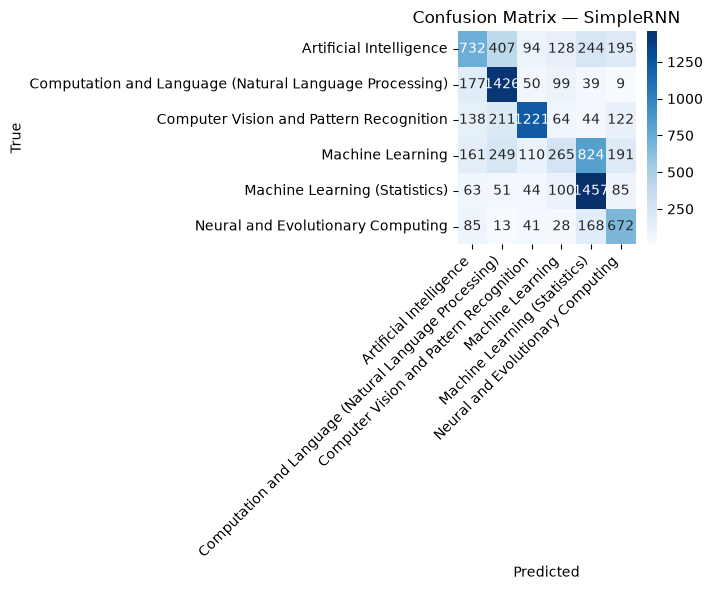

Best config for GRU: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7680)
=== GRU (test set) ===
Accuracy: 0.7600   Macro-F1: 0.7599   Weighted-F1: 0.7558
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.73      0.71      0.72      1800
Computation and Language (Natural Language Processing)       0.85      0.81      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.88      1800
                                      Machine Learning       0.62      0.52      0.57      1800
                         Machine Learning (Statistics)       0.72      0.78      0.75      1800
                     Neural and Evolutionary Computing       0.77      0.85      0.81      1007

                                              accuracy                           0.76     10007
                                             macr

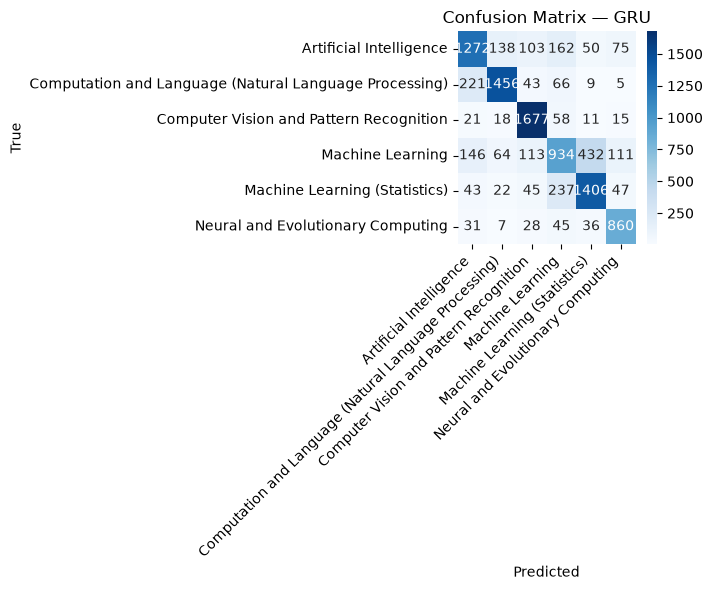

Best config for LSTM: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7613)
=== LSTM (test set) ===
Accuracy: 0.7514   Macro-F1: 0.7512   Weighted-F1: 0.7467
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.74      0.64      0.69      1800
Computation and Language (Natural Language Processing)       0.83      0.84      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.88      1800
                                      Machine Learning       0.60      0.52      0.56      1800
                         Machine Learning (Statistics)       0.71      0.78      0.74      1800
                     Neural and Evolutionary Computing       0.78      0.84      0.81      1007

                                              accuracy                           0.75     10007
                                             ma

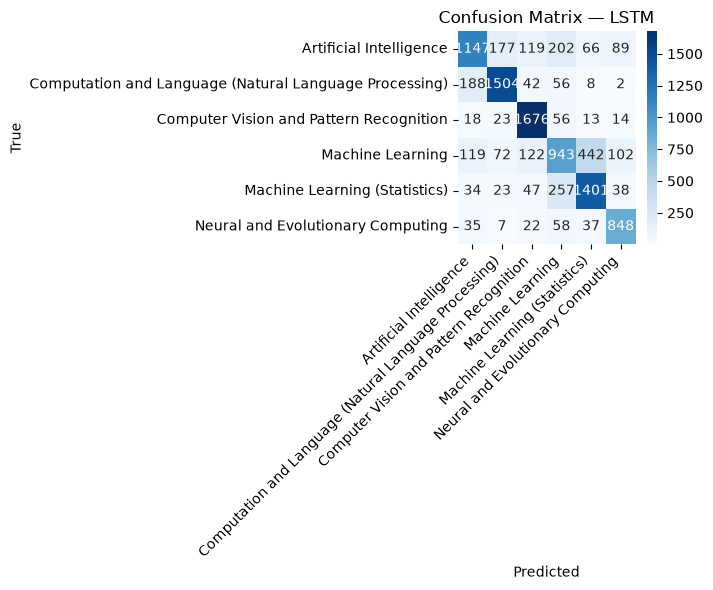

Best config for BiSimpleRNN: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7101)
=== BiSimpleRNN (test set) ===
Accuracy: 0.7182   Macro-F1: 0.7140   Weighted-F1: 0.7101
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.68      0.70      0.69      1800
Computation and Language (Natural Language Processing)       0.85      0.77      0.81      1800
               Computer Vision and Pattern Recognition       0.80      0.89      0.85      1800
                                      Machine Learning       0.60      0.39      0.47      1800
                         Machine Learning (Statistics)       0.62      0.83      0.71      1800
                     Neural and Evolutionary Computing       0.78      0.75      0.76      1007

                                              accuracy                           0.72     10007
                                 

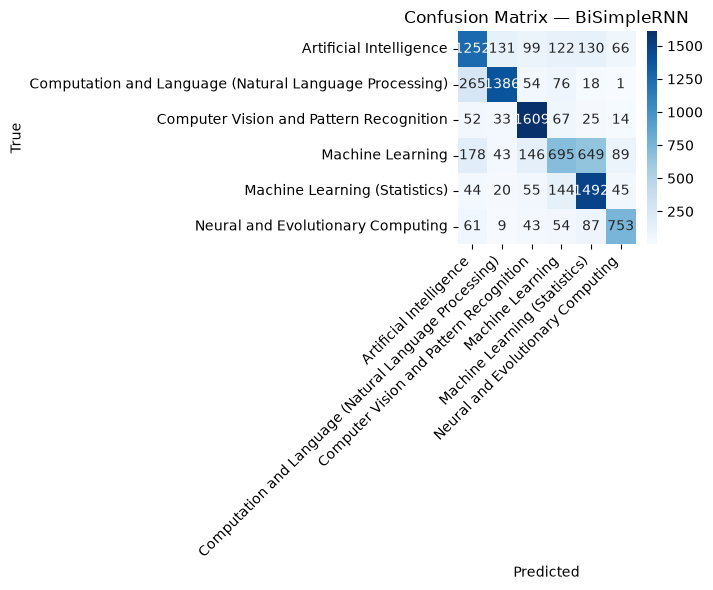

Best config for BiGRU: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7544)
=== BiGRU (test set) ===
Accuracy: 0.7586   Macro-F1: 0.7525   Weighted-F1: 0.7485
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.71      0.74      0.72      1800
Computation and Language (Natural Language Processing)       0.83      0.84      0.83      1800
               Computer Vision and Pattern Recognition       0.84      0.93      0.88      1800
                                      Machine Learning       0.70      0.42      0.52      1800
                         Machine Learning (Statistics)       0.70      0.81      0.75      1800
                     Neural and Evolutionary Computing       0.74      0.88      0.80      1007

                                              accuracy                           0.76     10007
                                             

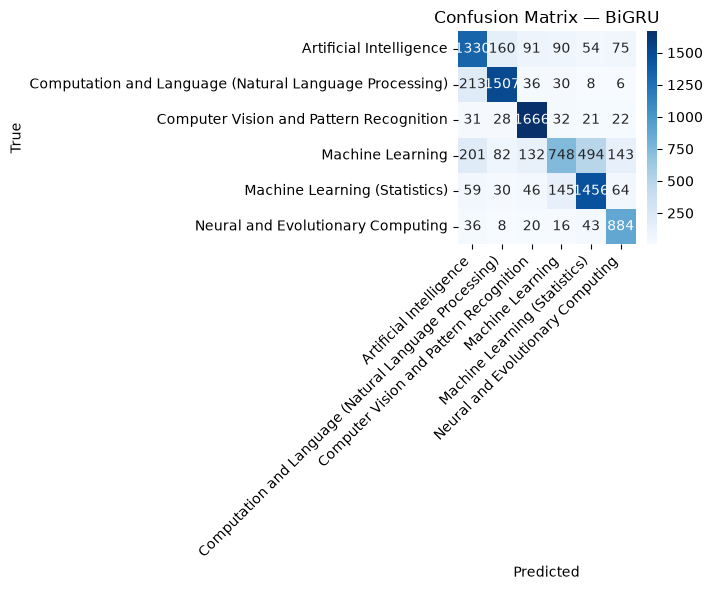

Best config for BiLSTM: {'units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}  (val_f1_macro=0.7542)
=== BiLSTM (test set) ===
Accuracy: 0.7529   Macro-F1: 0.7472   Weighted-F1: 0.7442
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.74      0.69      0.71      1800
Computation and Language (Natural Language Processing)       0.84      0.82      0.83      1800
               Computer Vision and Pattern Recognition       0.83      0.93      0.87      1800
                                      Machine Learning       0.66      0.44      0.52      1800
                         Machine Learning (Statistics)       0.69      0.83      0.75      1800
                     Neural and Evolutionary Computing       0.72      0.86      0.79      1007

                                              accuracy                           0.75     10007
                                           

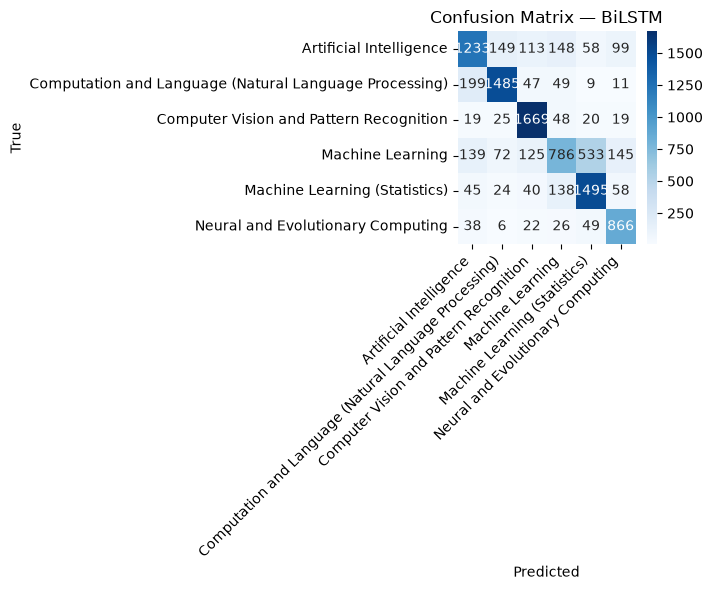

In [13]:
for cell_type, bidirectional in rnn_architectures:
    arch_name = ('Bi' if bidirectional else '') + cell_type
    best_row = best_config_row(tuning_log_df, arch_name)
    best_cfg = parse_config(best_row['config'])
    path = rnn_model_path(arch_name, best_cfg)
    best_model = rnn_trained_models.get((arch_name, best_row['config'])) or tf.keras.models.load_model(path)
    print(f'Best config for {arch_name}: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')

    val_or_test_pred = np.argmax(best_model.predict(X_test_seq, batch_size=BATCH_SIZE, verbose=0), axis=1)
    acc = accuracy_score(y_test, val_or_test_pred)
    f1_macro = f1_score(y_test, val_or_test_pred, average='macro')
    f1_weighted = f1_score(y_test, val_or_test_pred, average='weighted')
    cm = confusion_matrix(y_test, val_or_test_pred)
    report = classification_report(y_test, val_or_test_pred, target_names=label_encoder.classes_)

    print(f'=== {arch_name} (test set) ===')
    print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
    print(report)

    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f'Confusion Matrix — {arch_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    record_final_result(arch_name, acc, f1_macro, f1_weighted)

# 04 — BERT-base Fine-Tuning



## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)



In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

Reloaded 27 existing tuning_log rows from tuning_log.csv
Reloaded 9 existing final_results rows from final_results.csv


## 0. Reload Pipeline State from Notebook 1

In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

## 14. BERT-base Fine-Tuning

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset

print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

BERT_MODEL_NAME = 'bert-base-uncased'
BERT_MAX_LEN = 256

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

def to_hf_dataset(df_split, labels):
    return Dataset.from_dict({'text': df_split['clean_summary'].tolist(), 'label': labels.tolist()})


train_ds = to_hf_dataset(train_df, y_train)
val_ds = to_hf_dataset(val_df, y_val)
test_ds = to_hf_dataset(test_df, y_test)

def tokenize_fn(batch):
    return bert_tokenizer(batch['text'], truncation=True, padding='max_length', max_length=BERT_MAX_LEN)

train_ds = train_ds.map(tokenize_fn, batched=True)
val_ds = val_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

train_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
val_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
test_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

/home/halululu/NLP-Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
GPU: NVIDIA GeForce RTX 3060


Map: 100%|██████████| 10007/10007 [00:00<00:00, 13938.60 examples/s]


In [ ]:
from sklearn.metrics import accuracy_score as _acc, f1_score as _f1

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {'accuracy': _acc(labels, preds), 'f1_macro': _f1(labels, preds, average='macro')}


bert_configs = [
    {'learning_rate': 5e-5, 'per_device_train_batch_size': 16, 'num_train_epochs': 2},
    {'learning_rate': 3e-5, 'per_device_train_batch_size': 16, 'num_train_epochs': 2},
    {'learning_rate': 2e-5, 'per_device_train_batch_size': 8,  'num_train_epochs': 3},  # smaller batch, more epochs
]

bert_trained_models = {}  # config string -> saved model directory (not the Trainer object -- that doesn't survive restarts)

for i, cfg in enumerate(bert_configs):
    save_path = bert_model_path(cfg)
    already_trained = os.path.exists(os.path.join(save_path, 'config.json'))

    if already_trained:
        print(f'--- BERT config {i+1}/{len(bert_configs)}: {cfg} -- already trained, loading {save_path} ---')
        model = AutoModelForSequenceClassification.from_pretrained(save_path)
    else:
        print(f'--- BERT config {i+1}/{len(bert_configs)}: {cfg} ---')
        model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME, num_labels=num_classes)

    args = TrainingArguments(
        output_dir=f'./bert_run_{i}',
        learning_rate=cfg['learning_rate'],
        per_device_train_batch_size=cfg['per_device_train_batch_size'],
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=2 if cfg['per_device_train_batch_size'] == 8 else 1,  # keep effective batch ~16
        num_train_epochs=cfg['num_train_epochs'],
        eval_strategy='epoch',
        save_strategy='no',   # we save manually below, only once, after training -- not a checkpoint per epoch
        fp16=torch.cuda.is_available(),   # mixed precision -- essential for fitting BERT-base on 12GB
        logging_steps=100,
        seed=RANDOM_STATE,
        report_to='none',
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    if not already_trained:
        trainer.train()
        trainer.save_model(save_path)
        bert_tokenizer.save_pretrained(save_path)
        print(f'Trained and saved to {save_path}')

    val_metrics = trainer.evaluate()  # cheap either way -- just a forward pass over val_ds, not a retrain
    log_run('BERT-base', cfg, val_metrics['eval_accuracy'], val_metrics['eval_f1_macro'])
    bert_trained_models[str(cfg)] = save_path

--- BERT config 1/3: {'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2} ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1391.51it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.613126,0.658288,0.760044,0.757901
2,0.477254,0.626656,0.774935,0.776304


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.19s/it]


Trained and saved to saved_models/bert/1732b31bba


...

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.234403,0.648366,0.759844,0.759063
2,1.003427,0.638047,0.765541,0.767926
3,0.917779,0.649374,0.768139,0.769951


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.83s/it]


Trained and saved to saved_models/bert/b213a48c00


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.917779,0.649374,3,0.768139,0.769951


BERT-base              {'learning_rate': 2e-05, 'per_device_train_batch_size': 8, 'num_train_epochs': 3} val_acc=0.7681  val_f1_macro=0.7700


In [7]:
tuning_log_df = pd.DataFrame(tuning_log)  # refresh with BERT runs included
bert_log = tuning_log_df[tuning_log_df['model'] == 'BERT-base']
bert_log

,model,config,val_accuracy,val_f1_macro
27,BERT-base,"{'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}",0.774935,0.776304
28,BERT-base,"{'learning_rate': 3e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}",0.771237,0.771780
29,BERT-base,"{'learning_rate': 2e-05, 'per_device_train_batch_size': 8, 'num_train_epochs': 3}",0.768139,0.769951


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1374.22it/s]


Best BERT config: {'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}  (val_f1_macro=0.7763)


=== BERT-base (test set) ===
Accuracy: 0.7602   Macro-F1: 0.7608   Weighted-F1: 0.7566
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.71      0.70      0.71      1800
Computation and Language (Natural Language Processing)       0.83      0.85      0.84      1800
               Computer Vision and Pattern Recognition       0.85      0.90      0.88      1800
                                      Machine Learning       0.63      0.53      0.58      1800
                         Machine Learning (Statistics)       0.73      0.79      0.76      1800
                     Neural and Evolutionary Computing       0.80      0.82      0.81      1007

                                              accuracy                           0.76     10007
                                             macro avg       0.76      0.76      0.76     10007
                                          weigh

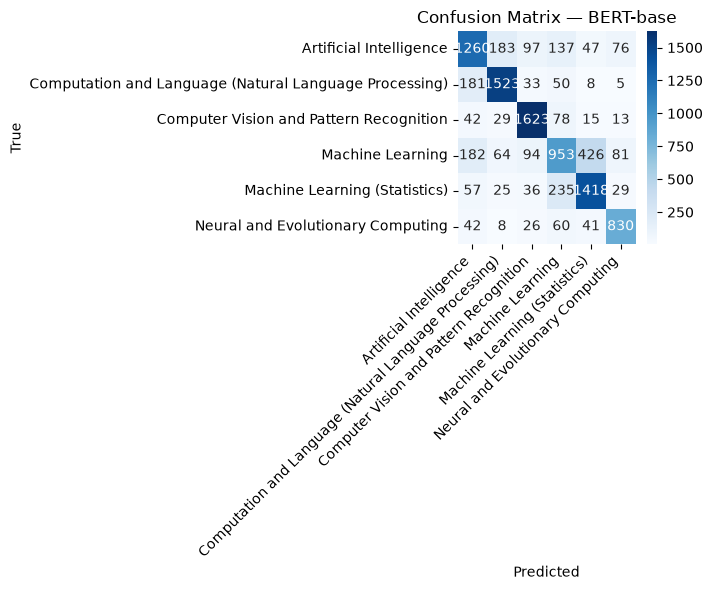

In [8]:
best_row = best_config_row(tuning_log_df, 'BERT-base')
best_cfg = parse_config(best_row['config'])
best_model_path = bert_trained_models.get(best_row['config']) or bert_model_path(best_cfg)
best_model = AutoModelForSequenceClassification.from_pretrained(best_model_path)
best_trainer = Trainer(model=best_model, compute_metrics=compute_metrics)  # eval-only Trainer, no training args needed
print(f'Best BERT config: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')

test_output = best_trainer.predict(test_ds)
test_pred = np.argmax(test_output.predictions, axis=1)

acc = accuracy_score(y_test, test_pred)
f1_macro = f1_score(y_test, test_pred, average='macro')
f1_weighted = f1_score(y_test, test_pred, average='weighted')
cm = confusion_matrix(y_test, test_pred)
report = classification_report(y_test, test_pred, target_names=label_encoder.classes_)

print('=== BERT-base (test set) ===')
print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
print(report)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix — BERT-base')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

record_final_result('BERT-base', acc, f1_macro, f1_weighted)

# 05 — Final Model Comparison

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

## 15. Final Model Comparison

In [ ]:
tuning_log_df = pd.read_csv(TUNING_LOG_PATH)
final_results_df = pd.read_csv(FINAL_RESULTS_PATH).sort_values('test_f1_macro', ascending=False).reset_index(drop=True)
final_results_df

,model,test_accuracy,test_f1_macro,test_f1_weighted
0,BERT-base,0.760168,0.760799,0.756636
1,GRU,0.759968,0.759888,0.755813
2,LogisticRegression,0.753872,0.756334,0.752240
3,BiGRU,0.758569,0.752487,0.748463
4,LSTM,0.751374,0.751200,0.746729
5,BiLSTM,0.752873,0.747246,0.744215
6,NaiveBayes,0.741181,0.739777,0.735899
7,RandomForest,0.723793,0.719141,0.712363
8,BiSimpleRNN,0.718197,0.713994,0.710147
9,SimpleRNN,0.576896,0.552686,0.549791


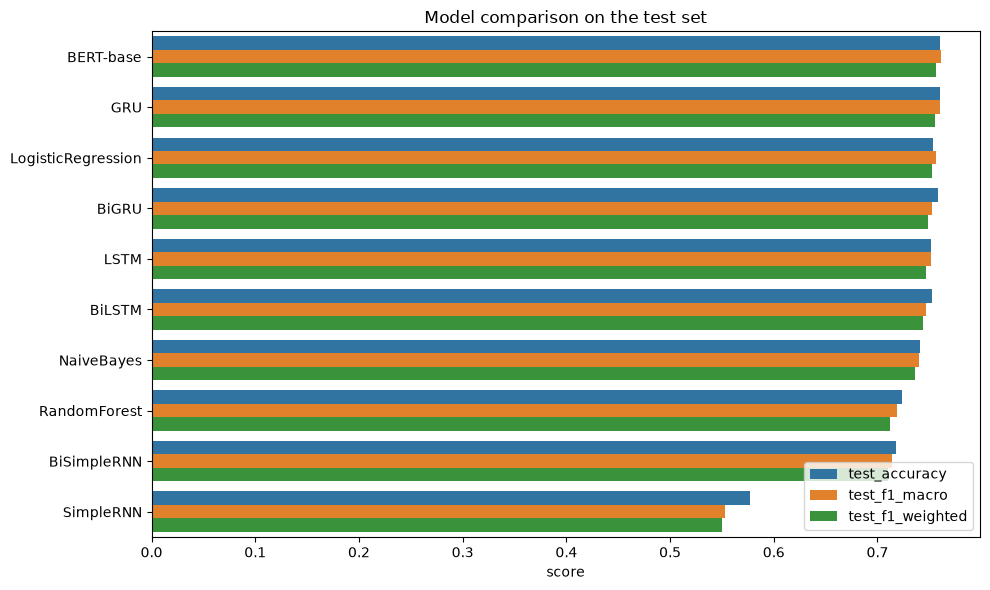

In [3]:
plt.figure(figsize=(10,6))
plot_df = final_results_df.melt(id_vars='model', value_vars=['test_accuracy', 'test_f1_macro', 'test_f1_weighted'],
                                 var_name='metric', value_name='score')
sns.barplot(data=plot_df, x='score', y='model', hue='metric')
plt.title('Model comparison on the test set')
plt.xlabel('score')
plt.ylabel('')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [4]:
best_model_row = final_results_df.iloc[0]
worst_model_row = final_results_df.iloc[-1]

print(f"Best-performing model:  {best_model_row['model']}  (test macro-F1 = {best_model_row['test_f1_macro']:.4f}, accuracy = {best_model_row['test_accuracy']:.4f})")
print(f"Worst-performing model: {worst_model_row['model']}  (test macro-F1 = {worst_model_row['test_f1_macro']:.4f}, accuracy = {worst_model_row['test_accuracy']:.4f})")

Best-performing model:  BERT-base  (test macro-F1 = 0.7608, accuracy = 0.7602)
Worst-performing model: SimpleRNN  (test macro-F1 = 0.5527, accuracy = 0.5769)


In [5]:
# Full hyperparameter tuning log (every config x every model, with validation metrics) -- for the report appendix.
tuning_log_df.sort_values(['model', 'val_f1_macro'], ascending=[True, False]).reset_index(drop=True)

,model,config,val_accuracy,val_f1_macro
0,BERT-base,"{'learning_rate': 5e-05, 'per_device_train_bat...",0.774935,0.776304
1,BERT-base,"{'learning_rate': 3e-05, 'per_device_train_bat...",0.771237,0.771780
2,BERT-base,"{'learning_rate': 2e-05, 'per_device_train_bat...",0.768139,0.769951
3,BiGRU,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.760544,0.754426
4,BiGRU,"{'units': 64, 'dropout': 0.2, 'learning_rate':...",0.754048,0.747651
5,BiGRU,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.754947,0.746161
6,BiLSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.759844,0.754209
7,BiLSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.754048,0.747622
8,BiLSTM,"{'units': 64, 'dropout': 0.2, 'learning_rate':...",0.751849,0.747217
9,BiSimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.715571,0.710138
